# UTS Pemodelan dan Simulasi — Laporan Case Solving (Soal Nomor 4)
**Optimasi Pemilihan Paket Layanan Keamanan Siber (Penetration Testing dan Security Audit) dengan Pemrograman Linear Metode Grafik**

Kelas F — Program Studi Informatika, FMIPA, Universitas Udayana — 2026

Penyelesaian dilakukan dengan langkah-langkah:
- **Formulasi model**: (1) identifikasi tujuan, (2) identifikasi variabel, (3) konstruksi fungsi, (4) penetapan batasan, (5) syarat non negatif.
- **Penyelesaian grafik**: (1) menentukan titik potong setiap batasan, (2) menggambar grafik, (3) menentukan titik-titik sudut, (4) membuat tabel optimal, (5) membuat kesimpulan.

## Soal Nomor 4
> Perusahaan konsultan keamanan siber menawarkan dua layanan analisis kerentanan, yaitu Penetration Testing dan Security Audit. Setiap paket Penetration Testing membutuhkan 4 jam kerja konsultan senior dan 2 jam kerja konsultan junior, dengan keuntungan sebesar Rp. 12.000.000. Setiap paket Security Audit membutuhkan 2 jam kerja konsultan senior dan 3 jam kerja konsultan junior, dengan keuntungan sebesar Rp. 10.000.000. Perusahaan memiliki alokasi waktu maksimal 40 jam kerja konsultan senior dan 36 jam kerja konsultan junior per minggu. Berapa banyak paket Penetration Testing dan Security Audit yang harus diambil untuk memaksimalkan keuntungan?

## Tabel Data Soal
| Constraint \| Paket | Penetration Testing | Security Audit | Kapasitas (per minggu) |
|---|---|---|---|
| Jam konsultan senior | 4 | 2 | 40 |
| Jam konsultan junior | 2 | 3 | 36 |
| Keuntungan/Paket | 12.000.000 | 10.000.000 | |

In [1]:
from fractions import Fraction as Fr
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog

# Data soal nomor 4
c = [12_000_000, 10_000_000]          # keuntungan/paket: [Pen. Testing, Sec. Audit]
A = [[4, 2],                          # jam konsultan senior per paket
     [2, 3]]                          # jam konsultan junior per paket
b = [40, 36]                          # kapasitas jam per minggu
nama_kendala = ['Senior', 'Junior']

def rp(v):
    # format rupiah dengan pemisah ribuan titik, contoh 152000000 -> 152.000.000
    return f"{int(round(v)):,}".replace(',', '.')

print('Data soal:')
for nm, (a1, a2), bi in zip(nama_kendala, A, b):
    print(f'  Jam konsultan {nm:6s}: {a1}x + {a2}y <= {bi}')
print(f'  Keuntungan: Penetration Testing = Rp {rp(c[0])}, '
      f'Security Audit = Rp {rp(c[1])}')

Data soal:
  Jam konsultan Senior: 4x + 2y <= 40
  Jam konsultan Junior: 2x + 3y <= 36
  Keuntungan: Penetration Testing = Rp 12.000.000, Security Audit = Rp 10.000.000


## Formulasi Model (Langkah Pemrograman Linear)
1. **Identifikasi Tujuan**: memaksimalkan keuntungan perusahaan dari paket Penetration Testing dan Security Audit yang diambil.
2. **Identifikasi Variabel**: $x$ = jumlah paket Penetration Testing, $y$ = jumlah paket Security Audit (per minggu).
3. **Konstruksi Fungsi**: keuntungan satu paket Penetration Testing Rp 12.000.000 dan satu paket Security Audit Rp 10.000.000, sehingga
$$f_{max} = 12.000.000x + 10.000.000y$$
4. **Penetapan Batasan**: batasan adalah jam kerja konsultan senior (maksimal 40 jam) dan jam kerja konsultan junior (maksimal 36 jam) per minggu, sehingga
   - Senior: $4x + 2y \le 40$
   - Junior: $2x + 3y \le 36$
5. **Tentukan Syarat Non Negatif**: $x, y \ge 0$

In [2]:
print('Model matematika:')
print(f'  fmax = {rp(c[0])}x + {rp(c[1])}y')
print('  Kendala:')
for k, (nm, (a1, a2), bi) in enumerate(zip(nama_kendala, A, b), 1):
    print(f'    Kendala {k} ({nm}): {a1}x + {a2}y <= {bi}')
print('  Syarat non negatif: x, y >= 0')

Model matematika:
  fmax = 12.000.000x + 10.000.000y
  Kendala:
    Kendala 1 (Senior): 4x + 2y <= 40
    Kendala 2 (Junior): 2x + 3y <= 36
  Syarat non negatif: x, y >= 0


## Penyelesaian
### Langkah 1 — Menentukan Titik Potong Setiap Batasan
Setiap kendala diubah menjadi persamaan garis, lalu dicari perpotongannya dengan sumbu $x$ ($y = 0$) dan sumbu $y$ ($x = 0$).

**Kendala 1: $4x + 2y \le 40$**
- Perpotongan dengan sumbu x, y = 0: $4x + 2 \cdot 0 = 40 \Rightarrow x = 10$ | $(10, 0)$
- Perpotongan dengan sumbu y, x = 0: $4 \cdot 0 + 2y = 40 \Rightarrow y = 20$ | $(0, 20)$

**Kendala 2: $2x + 3y \le 36$**
- Perpotongan dengan sumbu x, y = 0: $2x + 3 \cdot 0 = 36 \Rightarrow x = 18$ | $(18, 0)$
- Perpotongan dengan sumbu y, x = 0: $2 \cdot 0 + 3y = 36 \Rightarrow y = 12$ | $(0, 12)$

Syarat positif: $x, y \ge 0$

In [3]:
titik_potong = {}
for k, (nm, (a1, a2), bi) in enumerate(zip(nama_kendala, A, b), 1):
    tx = (Fr(bi, a1), Fr(0))   # y = 0
    ty = (Fr(0), Fr(bi, a2))   # x = 0
    titik_potong[k] = (tx, ty)
    print(f'Kendala {k}: {a1}x + {a2}y = {bi}')
    print(f'  sumbu x (y = 0): x = {bi}/{a1} = {tx[0]}  -> ({tx[0]}, 0)')
    print(f'  sumbu y (x = 0): y = {bi}/{a2} = {ty[1]}  -> (0, {ty[1]})')

Kendala 1: 4x + 2y = 40
  sumbu x (y = 0): x = 40/4 = 10  -> (10, 0)
  sumbu y (x = 0): y = 40/2 = 20  -> (0, 20)
Kendala 2: 2x + 3y = 36
  sumbu x (y = 0): x = 36/2 = 18  -> (18, 0)
  sumbu y (x = 0): y = 36/3 = 12  -> (0, 12)


### Langkah 2 — Menggambar Grafik
Garis kendala digambar dari titik-titik potong pada Langkah 1. Karena kedua kendala bertanda $\le$, daerah yang memenuhi berada di bawah/kiri setiap garis, dan dengan $x, y \ge 0$ daerah tersebut berada pada kuadran I. Irisan semua daerah tersebut adalah **daerah layak (feasible region)** yang diarsir.

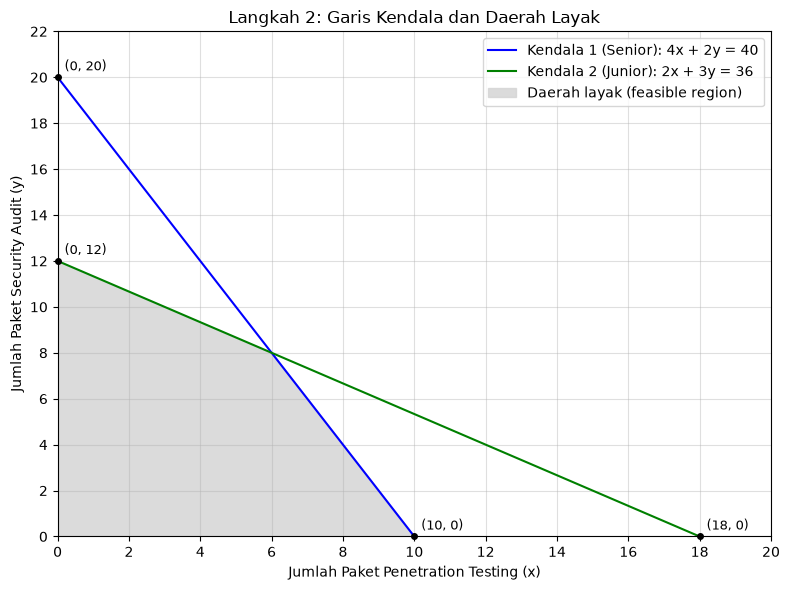

In [4]:
xs = np.linspace(0, 20, 400)
y1 = (b[0] - A[0][0]*xs) / A[0][1]      # 4x + 2y = 40
y2 = (b[1] - A[1][0]*xs) / A[1][1]      # 2x + 3y = 36

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(xs, y1, 'b-', label='Kendala 1 (Senior): 4x + 2y = 40')
ax.plot(xs, y2, 'g-', label='Kendala 2 (Junior): 2x + 3y = 36')
batas = np.maximum(0, np.minimum(y1, y2))
ax.fill_between(xs, 0, batas, where=batas > 0, color='lightgray', alpha=0.8,
                label='Daerah layak (feasible region)')
for k, (tx, ty) in titik_potong.items():
    for t in (tx, ty):
        ax.plot(float(t[0]), float(t[1]), 'ko', ms=4, clip_on=False)
        ax.annotate(f'({t[0]}, {t[1]})', (float(t[0]), float(t[1])), textcoords='offset points', xytext=(5, 5), fontsize=9)
ax.set_xlim(0, 20); ax.set_ylim(0, 22)
ax.set_xticks(range(0, 21, 2)); ax.set_yticks(range(0, 23, 2))
ax.set_xlabel('Jumlah Paket Penetration Testing (x)'); ax.set_ylabel('Jumlah Paket Security Audit (y)')
ax.set_title('Langkah 2: Garis Kendala dan Daerah Layak')
ax.grid(True, alpha=0.4); ax.legend(loc='upper right')
fig.tight_layout()
fig.savefig('grafik_langkah2.png', dpi=200)
plt.show()

### Langkah 3 — Menentukan Titik-Titik Sudut
- Sudut A pada titik $(0, 0)$
- Sudut B pada titik $(10, 0)$ — titik potong Kendala 1 dengan sumbu x (titik $(18, 0)$ tidak layak karena $4 \cdot 18 = 72 > 40$)
- Sudut C: perpotongan Kendala 1 dan Kendala 2. Sederhanakan persamaan 2 kemudian substitusi ke persamaan 1:

$$
\begin{aligned}
2x + 3y &= 36\\
x &= 18 - 1{,}5y\\[4pt]
4x + 2y &= 40\\
4(18 - 1{,}5y) + 2y &= 40\\
72 - 6y + 2y &= 40\\
-4y &= -32\\
y &= 8\\[4pt]
2x + 3y &= 36\\
2x + 3(8) &= 36\\
2x &= 12\\
x &= 6
\end{aligned}
$$
Sudut C pada titik $(6, 8)$
- Sudut D pada titik $(0, 12)$ — titik potong Kendala 2 dengan sumbu y (titik $(0, 20)$ tidak layak karena $3 \cdot 20 = 60 > 36$)

Program di bawah memverifikasi secara sistematis: semua perpotongan dua garis (kendala dan sumbu) dihitung secara eksak dengan pecahan, lalu hanya titik yang memenuhi semua kendala yang dipakai sebagai titik sudut.

In [5]:
# Garis batas dalam bentuk a1*x + a2*y = bi (termasuk sumbu x = 0 dan y = 0)
garis = [(Fr(a1), Fr(a2), Fr(bi), f'Kendala {k}')
         for k, ((a1, a2), bi) in enumerate(zip(A, b), 1)]
garis += [(Fr(1), Fr(0), Fr(0), 'sumbu y (x = 0)'),
          (Fr(0), Fr(1), Fr(0), 'sumbu x (y = 0)')]

def layak(x, y):
    return x >= 0 and y >= 0 and all(a1*x + a2*y <= bi for (a1, a2), bi in zip(A, b))

kandidat = []
for (a1, a2, b1, n1), (c1, c2, b2, n2) in combinations(garis, 2):
    det = a1*c2 - a2*c1
    if det == 0:
        continue                       # garis sejajar
    x = (b1*c2 - a2*b2) / det          # aturan Cramer (eksak)
    y = (a1*b2 - b1*c1) / det
    kandidat.append((x, y, f'{n1} & {n2}', layak(x, y)))

print('Semua perpotongan garis:')
for x, y, asal, ok in kandidat:
    status = 'layak' if ok else 'tidak layak'
    print(f'  ({str(x):>3}, {str(y):>3})  {asal:32s} -> {status}')

# urutkan titik sudut berlawanan arah jarum jam, dimulai dari (0, 0): A, B, C, D, ...
titik = list({(x, y) for x, y, _, ok in kandidat if ok})
cx = sum(float(p[0]) for p in titik) / len(titik)   # titik pusat daerah layak
cy = sum(float(p[1]) for p in titik) / len(titik)
sudut = sorted(titik, key=lambda p: np.arctan2(float(p[1]) - cy, float(p[0]) - cx))
i0 = sudut.index((0, 0)); sudut = sudut[i0:] + sudut[:i0]
label = 'ABCDEFG'
print('\nTitik sudut daerah layak:')
for L, (x, y) in zip(label, sudut):
    print(f'  Sudut {L} pada titik ({x}, {y})')

Semua perpotongan garis:
  (  6,   8)  Kendala 1 & Kendala 2            -> layak
  (  0,  20)  Kendala 1 & sumbu y (x = 0)      -> tidak layak
  ( 10,   0)  Kendala 1 & sumbu x (y = 0)      -> layak
  (  0,  12)  Kendala 2 & sumbu y (x = 0)      -> layak
  ( 18,   0)  Kendala 2 & sumbu x (y = 0)      -> tidak layak
  (  0,   0)  sumbu y (x = 0) & sumbu x (y = 0) -> layak

Titik sudut daerah layak:
  Sudut A pada titik (0, 0)
  Sudut B pada titik (10, 0)
  Sudut C pada titik (6, 8)
  Sudut D pada titik (0, 12)


### Langkah 4 — Membuat Tabel Optimal
Fungsi tujuan $f_{max} = 12.000.000x + 10.000.000y$ dievaluasi pada setiap titik sudut.

In [6]:
baris = []
for L, (x, y) in zip(label, sudut):
    f1, f2 = c[0]*x, c[1]*y
    baris.append({'Sudut': L, 'Titik': f'({x}, {y})',
                  'fmax = 12.000.000x + 10.000.000y':
                      f'f = {rp(f1)} + {rp(f2)} = {rp(f1 + f2)}',
                  'f': int(f1 + f2)})
tabel = pd.DataFrame(baris)
print(tabel.drop(columns='f').to_string(index=False))
i_opt = tabel['f'].idxmax()
x_opt, y_opt = sudut[i_opt]
f_opt = tabel.loc[i_opt, 'f']
print(f'\nfmax = {rp(f_opt)} pada Sudut {tabel.loc[i_opt, "Sudut"]} ({x_opt}, {y_opt})')

Sudut   Titik          fmax = 12.000.000x + 10.000.000y
    A  (0, 0)                             f = 0 + 0 = 0
    B (10, 0)         f = 120.000.000 + 0 = 120.000.000
    C  (6, 8) f = 72.000.000 + 80.000.000 = 152.000.000
    D (0, 12)         f = 0 + 120.000.000 = 120.000.000

fmax = 152.000.000 pada Sudut C (6, 8)


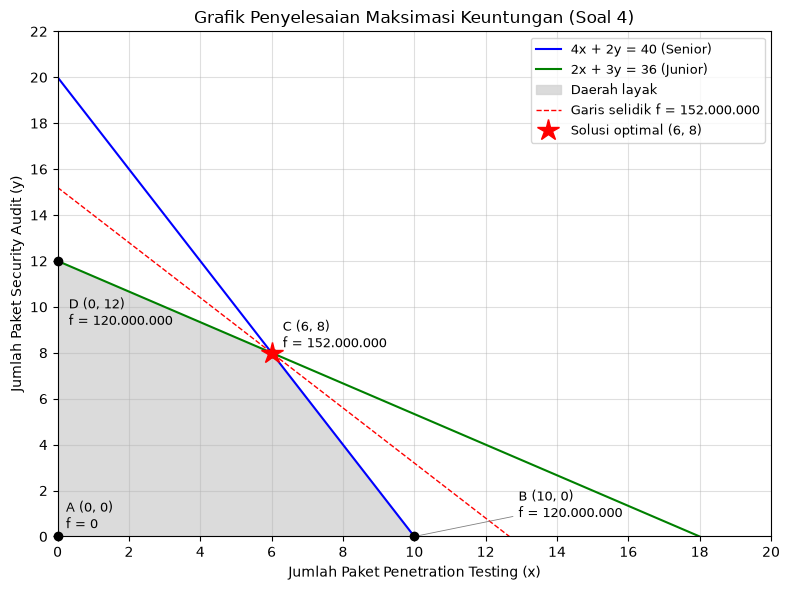

Grafik disimpan: grafik_soal4.png


In [7]:
# Grafik akhir: daerah layak, titik sudut berlabel, titik optimal, dan garis selidik f = fmax
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(xs, y1, 'b-', label='4x + 2y = 40 (Senior)')
ax.plot(xs, y2, 'g-', label='2x + 3y = 36 (Junior)')
ax.fill_between(xs, 0, batas, where=batas > 0, color='lightgray', alpha=0.8, label='Daerah layak')
yz = (f_opt - c[0]*xs) / c[1]
ax.plot(xs, yz, 'r--', lw=1, label=f'Garis selidik f = {rp(f_opt)}')
geser = {'A': (6, 6), 'B': (75, 14), 'C': (8, 4), 'D': (8, -46)}
for L, (x, y), fv in zip(label, sudut, tabel['f']):
    ax.plot(float(x), float(y), 'ko', ms=6, clip_on=False, zorder=5)
    ax.annotate(f'{L} ({x}, {y})\nf = {rp(fv)}', (float(x), float(y)), textcoords='offset points',
                xytext=geser.get(L, (6, 6)), fontsize=9,
                arrowprops=dict(arrowstyle='-', lw=0.6, color='gray') if L == 'B' else None)
ax.plot(float(x_opt), float(y_opt), 'r*', ms=16, zorder=6, label=f'Solusi optimal ({x_opt}, {y_opt})')
ax.set_xlim(0, 20); ax.set_ylim(0, 22)
ax.set_xticks(range(0, 21, 2)); ax.set_yticks(range(0, 23, 2))
ax.set_xlabel('Jumlah Paket Penetration Testing (x)'); ax.set_ylabel('Jumlah Paket Security Audit (y)')
ax.set_title('Grafik Penyelesaian Maksimasi Keuntungan (Soal 4)')
ax.grid(True, alpha=0.4); ax.legend(loc='upper right', fontsize=9)
fig.tight_layout()
fig.savefig('grafik_soal4.png', dpi=200)
plt.show()
print('Grafik disimpan: grafik_soal4.png')

### Analisis Kendala Aktif (Binding) dan Sensitivitas
Analisis ini dihitung secara manual (substitusi titik, kemiringan garis, dan penyelesaian sistem persamaan dengan `numpy.linalg.solve`), melanjutkan hasil grafik pada Langkah 1–4.
- **Slack** = kapasitas − pemakaian. Slack $= 0$ berarti kendala aktif (*binding*), yaitu sumber daya habis terpakai.
- **Rentang optimalitas**: titik C tetap optimal selama kemiringan garis tujuan berada di antara kemiringan Kendala 1 dan Kendala 2.
- **Harga bayangan (shadow price)** = tambahan keuntungan jika kapasitas suatu kendala ditambah 1 jam.

#### 1) Kendala Aktif (Binding)
Substitusi titik optimal C $(6, 8)$ ke setiap kendala:

**Kendala 1 (Senior): $4x + 2y \le 40$**
$$4(6) + 2(8) = 24 + 16 = 40 \;\Rightarrow\; \text{slack} = 40 - 40 = 0 \;\text{(binding)}$$

**Kendala 2 (Junior): $2x + 3y \le 36$**
$$2(6) + 3(8) = 12 + 24 = 36 \;\Rightarrow\; \text{slack} = 36 - 36 = 0 \;\text{(binding)}$$

In [8]:
# 1) Kendala aktif: substitusi titik optimal C ke setiap kendala (ruas kiri, ruas kanan, slack)
baris_binding = []
for k, (nm, (a1, a2), bi) in enumerate(zip(nama_kendala, A, b), 1):
    lhs = a1*x_opt + a2*y_opt
    s = bi - lhs
    print(f'Kendala {k} ({nm}): {a1}({x_opt}) + {a2}({y_opt}) = {a1*x_opt} + {a2*y_opt} = {lhs} ; '
          f'slack = {bi} - {lhs} = {s}')
    baris_binding.append({'Kendala': f'Kendala {k} (Jam konsultan {nm})',
                          'Ruas kiri (pemakaian)': str(lhs), 'Ruas kanan (kapasitas)': bi,
                          'Slack': str(s), 'Status': 'Binding' if s == 0 else 'Tidak binding'})
tabel_binding = pd.DataFrame(baris_binding)
print()
print(tabel_binding.to_string(index=False))

Kendala 1 (Senior): 4(6) + 2(8) = 24 + 16 = 40 ; slack = 40 - 40 = 0
Kendala 2 (Junior): 2(6) + 3(8) = 12 + 24 = 36 ; slack = 36 - 36 = 0

                         Kendala Ruas kiri (pemakaian)  Ruas kanan (kapasitas) Slack  Status
Kendala 1 (Jam konsultan Senior)                    40                      40     0 Binding
Kendala 2 (Jam konsultan Junior)                    36                      36     0 Binding


#### 2) Sensitivitas Koefisien Fungsi Tujuan (Metode Kemiringan)
Setiap garis $a_1x + a_2y = b$ memiliki kemiringan $m = -a_1/a_2$:
- Kendala 1 (Senior): $4x + 2y = 40 \Rightarrow m_1 = -4/2 = -2$
- Kendala 2 (Junior): $2x + 3y = 36 \Rightarrow m_2 = -2/3$
- Fungsi tujuan: $f = c_1x + c_2y \Rightarrow m_f = -c_1/c_2 = -12.000.000/10.000.000 = -1{,}2$

Titik C tetap optimal selama garis selidik berada di antara kedua garis kendala yang melalui C:
$$-2 \le -\frac{c_1}{c_2} \le -\frac{2}{3} \quad\Longleftrightarrow\quad \frac{2}{3} \le \frac{c_1}{c_2} \le 2$$
Karena $c_1/c_2 = 1{,}2$ berada di dalam rentang tersebut, titik C $(6, 8)$ optimal.
- Jika $c_2 = 10.000.000$ tetap: $\tfrac{2}{3}(10.000.000) \le c_1 \le 2(10.000.000) \Rightarrow 6.666.667 \le c_1 \le 20.000.000$
- Jika $c_1 = 12.000.000$ tetap: $\tfrac{12.000.000}{2} \le c_2 \le \tfrac{12.000.000}{2/3} \Rightarrow 6.000.000 \le c_2 \le 18.000.000$

In [9]:
# 2) Sensitivitas koefisien tujuan melalui kemiringan garis (dihitung, bukan diketik manual)
m1 = Fr(-A[0][0], A[0][1])            # kemiringan Kendala 1 (Senior)
m2 = Fr(-A[1][0], A[1][1])            # kemiringan Kendala 2 (Junior)
mf = Fr(-c[0], c[1])                  # kemiringan garis tujuan
print(f'Kemiringan Kendala 1 (Senior): m1 = -{A[0][0]}/{A[0][1]} = {m1}')
print(f'Kemiringan Kendala 2 (Junior): m2 = -{A[1][0]}/{A[1][1]} = {m2}')
print(f'Kemiringan fungsi tujuan     : mf = -c1/c2 = -{rp(c[0])}/{rp(c[1])} = {float(mf)}')

r_min, r_max = sorted([-m1, -m2])     # batas rasio c1/c2
rasio = Fr(c[0], c[1])
print(f'\nTitik C tetap optimal jika {r_min} <= c1/c2 <= {r_max}; '
      f'saat ini c1/c2 = {float(rasio)} -> {"optimal" if r_min <= rasio <= r_max else "tidak optimal"}')

c1_min, c1_max = r_min*c[1], r_max*c[1]   # c2 tetap
c2_min, c2_max = c[0]/r_max, c[0]/r_min   # c1 tetap
tabel_rentang = pd.DataFrame([
    {'Koefisien': 'c1 (Penetration Testing)', 'Nilai saat ini': rp(c[0]),
     'Batas bawah': rp(c1_min), 'Batas atas': rp(c1_max), 'Syarat': f'c2 tetap = {rp(c[1])}'},
    {'Koefisien': 'c2 (Security Audit)', 'Nilai saat ini': rp(c[1]),
     'Batas bawah': rp(c2_min), 'Batas atas': rp(c2_max), 'Syarat': f'c1 tetap = {rp(c[0])}'}])
print()
print(tabel_rentang.to_string(index=False))

Kemiringan Kendala 1 (Senior): m1 = -4/2 = -2
Kemiringan Kendala 2 (Junior): m2 = -2/3 = -2/3
Kemiringan fungsi tujuan     : mf = -c1/c2 = -12.000.000/10.000.000 = -1.2

Titik C tetap optimal jika 2/3 <= c1/c2 <= 2; saat ini c1/c2 = 1.2 -> optimal

               Koefisien Nilai saat ini Batas bawah Batas atas                Syarat
c1 (Penetration Testing)     12.000.000   6.666.667 20.000.000 c2 tetap = 10.000.000
     c2 (Security Audit)     10.000.000   6.000.000 18.000.000 c1 tetap = 12.000.000


#### 3) Harga Bayangan (Shadow Price)
Kapasitas setiap kendala ditambah 1 jam, lalu titik potong kedua garis kendala (titik C baru) diselesaikan kembali:

**Senior 40 → 41** (Junior tetap 36):
$$\begin{aligned} 4x + 2y &= 41\\ 2x + 3y &= 36 \end{aligned} \;\Rightarrow\; (x, y) = (6{,}375;\ 7{,}75),\quad f = 12.000.000(6{,}375) + 10.000.000(7{,}75) = 154.000.000$$
$\Delta f = 154.000.000 - 152.000.000 = 2.000.000$ per jam konsultan senior.

**Junior 36 → 37** (Senior tetap 40):
$$\begin{aligned} 4x + 2y &= 40\\ 2x + 3y &= 37 \end{aligned} \;\Rightarrow\; (x, y) = (5{,}75;\ 8{,}5),\quad f = 12.000.000(5{,}75) + 10.000.000(8{,}5) = 154.000.000$$
$\Delta f = 154.000.000 - 152.000.000 = 2.000.000$ per jam konsultan junior.

Catatan: harga bayangan ini hanya berlaku selama titik potong kedua kendala masih layak ($x \ge 0$, $y \ge 0$), yaitu selama kedua kendala tetap menjadi kendala aktif yang membentuk titik optimal.

In [10]:
# 3) Harga bayangan: tambah kapasitas 1 jam, selesaikan perpotongan kedua kendala dengan numpy.linalg.solve
A_np = np.array(A, dtype=float)
b_np = np.array(b, dtype=float)
f_awal = c[0]*float(x_opt) + c[1]*float(y_opt)
baris_sp = []
for k, nm in enumerate(nama_kendala):
    b_baru = b_np.copy()
    b_baru[k] += 1
    xb, yb = np.linalg.solve(A_np, b_baru)
    f_baru = c[0]*xb + c[1]*yb
    masih_layak = xb >= 0 and yb >= 0
    print(f'Kendala {k+1} ({nm}) {int(b_np[k])} -> {int(b_baru[k])}: '
          f'(x, y) = ({xb:g}, {yb:g}), f = {rp(f_baru)}, delta f = {rp(f_baru - f_awal)}, '
          f'titik layak: {masih_layak}')
    baris_sp.append({'Kendala': f'Jam konsultan {nm}', 'Kapasitas baru': int(b_baru[k]),
                     'Titik C baru': f'({xb:g}, {yb:g})', 'f baru': rp(f_baru),
                     'Shadow price (Rp/jam)': rp(f_baru - f_awal)})
tabel_sp = pd.DataFrame(baris_sp)
print(f'\nf awal = {rp(f_awal)}')
print(tabel_sp.to_string(index=False))

Kendala 1 (Senior) 40 -> 41: (x, y) = (6.375, 7.75), f = 154.000.000, delta f = 2.000.000, titik layak: True
Kendala 2 (Junior) 36 -> 37: (x, y) = (5.75, 8.5), f = 154.000.000, delta f = 2.000.000, titik layak: True

f awal = 152.000.000
             Kendala  Kapasitas baru  Titik C baru      f baru Shadow price (Rp/jam)
Jam konsultan Senior              41 (6.375, 7.75) 154.000.000             2.000.000
Jam konsultan Junior              37   (5.75, 8.5) 154.000.000             2.000.000


#### 4) Interpretasi untuk Perusahaan
- Kedua sumber daya (jam konsultan senior dan junior) **habis terpakai** pada solusi optimal $(6, 8)$; tidak ada jam kerja yang menganggur, sehingga keduanya menjadi pembatas keuntungan.
- Setiap tambahan **1 jam konsultan senior** atau **1 jam konsultan junior** menaikkan keuntungan sekitar **Rp 2.000.000**. Jika biaya lembur/tambahan jam konsultan lebih kecil dari Rp 2.000.000 per jam, penambahan kapasitas menguntungkan (selama titik potong kedua kendala masih layak).
- Komposisi 6 paket Penetration Testing dan 8 paket Security Audit tetap optimal selama keuntungan Penetration Testing berada di antara **Rp 6.666.667 – Rp 20.000.000** (Security Audit tetap Rp 10.000.000), atau keuntungan Security Audit berada di antara **Rp 6.000.000 – Rp 18.000.000** (Penetration Testing tetap Rp 12.000.000). Perubahan harga di dalam rentang ini hanya mengubah nilai keuntungan total, bukan jumlah paket yang diambil.

### Langkah 5 — Membuat Kesimpulan
$f = 12.000.000x + 10.000.000y$ mencapai nilai maksimum $= 152.000.000$ pada nilai $x = 6$ dan $y = 8$.

**Interpretasi:** Perusahaan konsultan keamanan siber sebaiknya mengambil **6 paket Penetration Testing** dan **8 paket Security Audit** per minggu untuk memperoleh **keuntungan maksimum Rp 152.000.000**. Pada kombinasi ini seluruh alokasi jam konsultan senior (4·6 + 2·8 = 40 jam) dan junior (2·6 + 3·8 = 36 jam) terpakai habis, sehingga kedua kendala bersifat *binding*.